# RespiraCidadão: Redes Neurais & Deep Learning (GS 2026.2)

Turma 1TIAPZ1, grupo Perceptron.

- Giovanni Henrique Pereira Hessel (RM 570574)
- Suellen Pereira da Silva (RM 573862)
- Israel Carneiro de Toledo (RM 573854)

## Etapa 1. Problema e papel da rede

Fumaça de queimada e trânsito pesado sobem o monóxido de carbono perto de escolas e UBS. Nosso nó comunitário (ESP32) mede dois sensores de gás, temperatura e umidade, e acende um LED com uma regra fixa. A regra é boa para funcionar sem internet, mas olha um sensor só.

A rede neural recebe as mesmas 4 leituras quando elas chegam à API e devolve a probabilidade de cada nível de risco: normal, atenção ou crítico. Quem usa a resposta é a coordenação da escola ou da UBS, que decide se fecha janelas, adia a educação física ou avisa os pacientes com asma.

## Etapa 2. Dataset

Usamos a UCI Air Quality (De Vito et al., 2008): 9.357 horas de uma estação com sensores de óxido metálico e analisadores de referência. Depois de tirar os códigos de falha (-200) ficam 6.941 horas completas.

- Entradas: as 4 leituras do ESP32. PT08.S1(CO) vira gas_co, PT08.S2(NMHC) vira gas_voc, T vira temperatura_c, RH vira umidade_pct.
- Alvo: o CO medido pelo analisador de referência, CO(GT), em 3 faixas. Abaixo de 1,5 mg/m³ é normal, de 1,5 a 3,0 é atenção, a partir de 3,0 é crítico. CO(GT) só define o rótulo, nunca entra como entrada.
- As classes não têm o mesmo tamanho (cerca de 37%, 39% e 24%), então além da acurácia olhamos o F1-macro.

Por que não as 11 variáveis da base? Três delas (C6H6, NOx, NO2) vêm de analisadores que custam dezenas de milhares de reais. No notebook de Machine Learning medimos: com as 11 o F1 sobe cerca de 1 ponto. Preferimos uma rede que roda com o que o ESP32 de fato mede.

In [1]:
import json
import random
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)

plt.rcParams.update({"figure.facecolor": "white", "axes.grid": True, "grid.alpha": 0.3})

ROOT = Path.cwd().resolve()
if ROOT.name == "neural-networks":
    ROOT = ROOT.parents[1]

DATA_PATH = ROOT / "data" / "processed" / "air_quality_clean.csv"
OUT_DIR = ROOT / "packages" / "neural-networks"
CHARTS_DIR = OUT_DIR / "charts"
ARTIFACTS_DIR = OUT_DIR / "artifacts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# Mesma ordem do JSON do ESP32: gas_co, gas_voc, temperatura_c, umidade_pct
FEATURES = ["PT08.S1(CO)", "PT08.S2(NMHC)", "T", "RH"]
CLASS_NAMES = ["normal", "atencao", "critico"]

df = pd.read_csv(DATA_PATH)
print(f"{len(df)} horas | ausentes nas entradas: {int(df[FEATURES].isna().sum().sum())}")
print(df["nivel_risco"].value_counts(normalize=True).round(3))
df[FEATURES + ["CO(GT)", "nivel_risco"]].head()

6941 horas | ausentes nas entradas: 0
nivel_risco
atencao    0.392
normal     0.365
critico    0.244
Name: proportion, dtype: float64


,PT08.S1(CO),PT08.S2(NMHC),T,RH,CO(GT),nivel_risco
0,1360.0,1046.0,13.6,48.9,2.6,atencao
1,1292.0,955.0,13.3,47.7,2.0,atencao
2,1402.0,939.0,11.9,54.0,2.2,atencao
3,1376.0,948.0,11.0,60.0,2.2,atencao
4,1272.0,836.0,11.2,59.6,1.6,atencao


## Etapa 3. Preparação sem vazamento

- Split estratificado: 70% treino, 15% validação, 15% teste.
- O StandardScaler aprende média e desvio só no treino e depois é aplicado em validação e teste.
- A validação decide o early stopping. O teste fica guardado até a Etapa 7.

In [2]:
X = df[FEATURES].to_numpy(dtype=np.float32)
y = df["nivel_risco_id"].to_numpy(dtype=np.int64)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = (scaler.transform(a).astype(np.float32) for a in (X_train, X_val, X_test))

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(torch.tensor(X_train_s), torch.tensor(y_train)), batch_size=64, shuffle=True, generator=g)
val_x, val_y = torch.tensor(X_val_s), torch.tensor(y_val)
print(f"Treino {X_train_s.shape} | Validação {X_val_s.shape} | Teste {X_test_s.shape}")

Treino (4858, 4) | Validação (1041, 4) | Teste (1042, 4)


## Etapa 4. Arquitetura

Cada leitura é uma linha com 4 números. Não há imagem (CNN) nem sequência fixa (RNN): o ESP32 manda uma leitura por vez e a API precisa responder na hora. Por isso usamos um MLP.

- ReLU nas camadas ocultas: barata e sem saturar o gradiente.
- CrossEntropyLoss com 3 saídas: é a perda padrão para classificação em 3 classes.
- Adam: ajusta o passo sozinho e converge em poucas dezenas de épocas.

Montamos dois modelos para comparar na Etapa 6:

- A, baseline: 4 → 128 → 64 → 3, sem regularização e com taxa de aprendizado alta. Esperamos que ele decore o treino.
- B, regularizado: 4 → 64 → 32 → 3 com BatchNorm, Dropout 0,25, weight_decay e early stopping (paciência de 15 épocas).

In [3]:
class BaselineMLP(nn.Module):
    def __init__(self, in_features: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 3),
        )

    def forward(self, x):
        return self.net(x)


class AirQualityMLP(nn.Module):
    """Mesma classe que a API carrega em apps/api/app/classifier.py."""

    def __init__(self, in_features: int, hidden_dims, num_classes: int = 3, dropout: float = 0.25):
        super().__init__()
        layers, prev = [], in_features
        for h in hidden_dims:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def accuracy_of(model, x, y_true):
    model.eval()
    with torch.no_grad():
        logits = model(x)
    return nn.functional.cross_entropy(logits, y_true).item(), (logits.argmax(1) == y_true).float().mean().item()


def train_model(model, epochs, lr, weight_decay=0.0, patience=None):
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss()
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0
    train_x, train_y = torch.tensor(X_train_s), torch.tensor(y_train)

    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in train_loader:
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            opt.step()

        # As duas curvas medidas em modo de avaliação, para comparar treino e validação de igual para igual
        tl, ta = accuracy_of(model, train_x, train_y)
        vl, va = accuracy_of(model, val_x, val_y)
        for k, v in zip(hist, (tl, vl, ta, va)):
            hist[k].append(v)

        if vl < best_loss - 1e-4:
            best_loss, best_epoch, wait = vl, epoch, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if patience is not None and wait >= patience:
                print(f"Early stopping na época {epoch}. Melhor val_loss {best_loss:.4f} na época {best_epoch}.")
                break

    if patience is not None:
        model.load_state_dict(best_state)
    hist["best_epoch"] = best_epoch
    return hist

## Etapas 5 e 6. Treino e comparação

Os dois modelos têm até 150 épocas. O baseline vai até o fim. O regularizado para quando a perda de validação passa 15 épocas sem melhorar e volta para os pesos da melhor época.

Early stopping na época 34. Melhor val_loss 0.3118 na época 19.


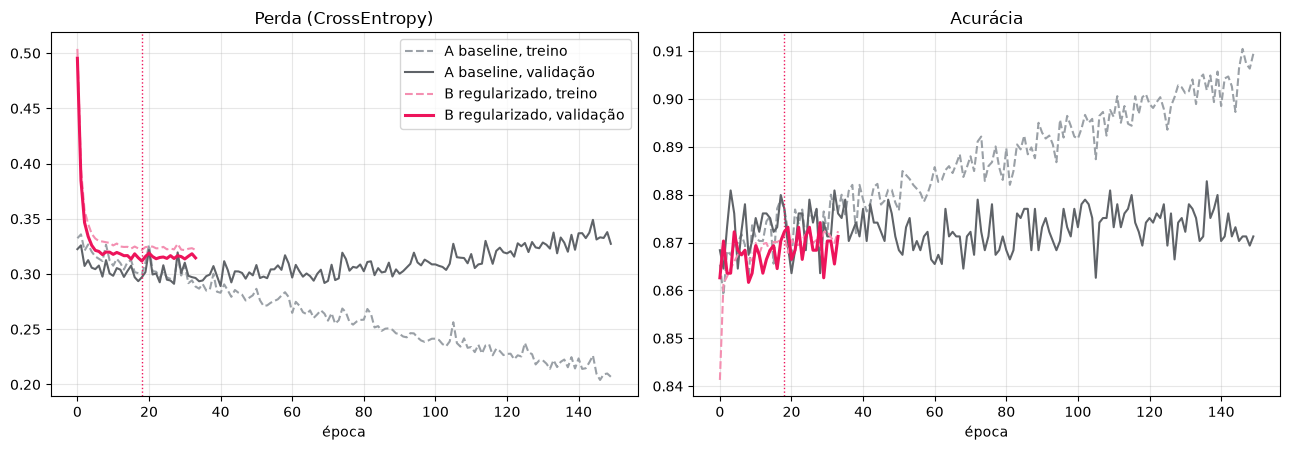

Baseline: 150 épocas | Regularizado: 34 épocas, melhor na 19


In [4]:
torch.manual_seed(SEED)
baseline = BaselineMLP(len(FEATURES))
hist_base = train_model(baseline, epochs=150, lr=3e-3)

torch.manual_seed(SEED)
reg_model = AirQualityMLP(len(FEATURES), hidden_dims=[64, 32], dropout=0.25)
hist_reg = train_model(reg_model, epochs=150, lr=1e-3, weight_decay=1e-4, patience=15)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, key, title in [(axes[0], "loss", "Perda (CrossEntropy)"), (axes[1], "acc", "Acurácia")]:
    ax.plot(hist_base[f"train_{key}"], color="#9AA0A6", ls="--", label="A baseline, treino")
    ax.plot(hist_base[f"val_{key}"], color="#5F6368", label="A baseline, validação")
    ax.plot(hist_reg[f"train_{key}"], color="#F48FB1", ls="--", label="B regularizado, treino")
    ax.plot(hist_reg[f"val_{key}"], color="#ED145B", lw=2.2, label="B regularizado, validação")
    ax.axvline(hist_reg["best_epoch"] - 1, color="#ED145B", ls=":", lw=1)
    ax.set_title(title)
    ax.set_xlabel("época")
axes[0].legend()
fig.tight_layout()
fig.savefig(CHARTS_DIR / "01_curvas_treinamento.png", dpi=150)
plt.show()
print(f"Baseline: {len(hist_base['train_loss'])} épocas | Regularizado: {len(hist_reg['train_loss'])} épocas, melhor na {hist_reg['best_epoch']}")

### O que as curvas mostram

- O baseline chega à menor perda de validação (0,289) na época 41. Depois disso a perda de treino continua caindo até 0,207 e a de validação sobe para 0,327 na época 150. Ele passou a decorar o treino. É overfitting, e é o que esperávamos de uma rede maior sem freio.
- O regularizado tem a melhor validação na época 19 (0,312) e o early stopping para na 34. As curvas de treino e validação ficam coladas o tempo todo.
- O baseline consegue uma perda de validação um pouco menor no melhor ponto dele, mas só se alguém escolher a época certa olhando a validação. Sem early stopping, ninguém faz isso.

## Etapa 7. Avaliação no teste

Agora sim usamos os 15% guardados. Comparamos as duas redes com a regra do ESP32 (gas_voc ≥ 830 é atenção, ≥ 1140 é crítico) no mesmo conjunto.

,modelo,epocas,train_acc,test_acc,test_f1_macro,gap
0,Regra do ESP32 (gas_voc),0,NaN,0.8244,0.8294,NaN
1,"A baseline (128-64, sem regularização)",150,0.9094,0.8570,0.8616,0.0524
2,"B regularizado (64-32, BN + Dropout + ES)",34,0.8718,0.8608,0.8646,0.0110


              precision    recall  f1-score   support

      normal       0.89      0.88      0.89       380
     atencao       0.82      0.83      0.82       408
     critico       0.90      0.87      0.88       254

    accuracy                           0.86      1042
   macro avg       0.87      0.86      0.86      1042
weighted avg       0.86      0.86      0.86      1042



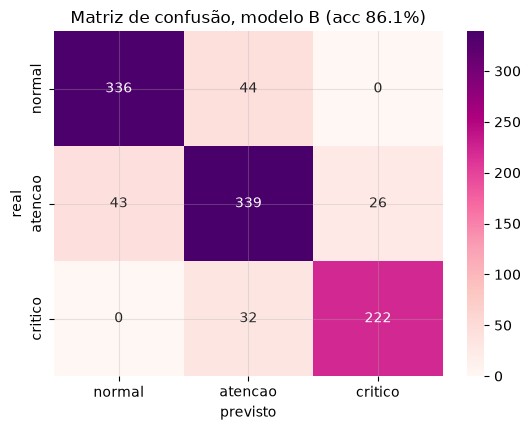

In [5]:
def evaluate(model, X_arr, y_true):
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(torch.tensor(X_arr)), dim=1).numpy()
    preds = probs.argmax(1)
    return {"accuracy": round(float(accuracy_score(y_true, preds)), 4),
            "f1_macro": round(float(f1_score(y_true, preds, average="macro")), 4),
            "preds": preds}

base_tr, base_te = evaluate(baseline, X_train_s, y_train), evaluate(baseline, X_test_s, y_test)
reg_tr, reg_te = evaluate(reg_model, X_train_s, y_train), evaluate(reg_model, X_test_s, y_test)

voc = X_test[:, 1]
regra = (voc >= 830).astype(int) + (voc >= 1140).astype(int)

comp_table = pd.DataFrame([
    {"modelo": "Regra do ESP32 (gas_voc)", "epocas": 0, "train_acc": None,
     "test_acc": round(float(accuracy_score(y_test, regra)), 4),
     "test_f1_macro": round(float(f1_score(y_test, regra, average="macro")), 4), "gap": None},
    {"modelo": "A baseline (128-64, sem regularização)", "epocas": len(hist_base["train_loss"]),
     "train_acc": base_tr["accuracy"], "test_acc": base_te["accuracy"], "test_f1_macro": base_te["f1_macro"],
     "gap": round(base_tr["accuracy"] - base_te["accuracy"], 4)},
    {"modelo": "B regularizado (64-32, BN + Dropout + ES)", "epocas": len(hist_reg["train_loss"]),
     "train_acc": reg_tr["accuracy"], "test_acc": reg_te["accuracy"], "test_f1_macro": reg_te["f1_macro"],
     "gap": round(reg_tr["accuracy"] - reg_te["accuracy"], 4)},
])
display(comp_table)
print(classification_report(y_test, reg_te["preds"], target_names=CLASS_NAMES))

cm_nn = confusion_matrix(y_test, reg_te["preds"])
fig, ax = plt.subplots(figsize=(5.6, 4.4))
sns.heatmap(cm_nn, annot=True, fmt="d", cmap="RdPu", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title(f"Matriz de confusão, modelo B (acc {reg_te['accuracy']:.1%})")
ax.set_xlabel("previsto")
ax.set_ylabel("real")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "02_matriz_confusao_nn.png", dpi=150)
plt.show()

### Leitura do teste

- O modelo B acerta 86,1% (F1-macro 0,865). O baseline acerta 85,7% (F1 0,862). A diferença de 0,4 ponto cabe no erro de amostragem de 1.042 casos. O ganho que dá para afirmar é outro: o gap entre treino e teste cai de 5,2 para 1,1 ponto.
- As duas redes ganham da regra do ESP32 (F1 0,829) em cerca de 3,5 pontos. É isso que justifica mandar a leitura para a API em vez de confiar só no LED.
- O Random Forest do notebook de Machine Learning fica em 0,874 com as mesmas 4 entradas. Em dados tabulares pequenos, rede neural não ganha de árvore. Mantemos as duas na API e mostramos as duas respostas lado a lado.
- Nenhuma hora normal foi prevista como crítica, e nenhuma crítica como normal. Todo erro fica entre classes vizinhas.

## Etapa 8. Exportação e demonstração com leituras novas

Salvamos os pesos (air_quality_mlp.pt) e o scaler com a lista de entradas (nn_metadata.joblib). A API carrega os dois e responde em POST /predict. Os 3 cenários abaixo não estão na base: são leituras que inventamos para uma manhã limpa, um fim de tarde de trânsito e uma queimada perto da escola.

In [6]:
torch.save(reg_model.state_dict(), ARTIFACTS_DIR / "air_quality_mlp.pt")
joblib.dump({"scaler": scaler, "features": FEATURES, "features_json": ["gas_co", "gas_voc", "temperatura_c", "umidade_pct"],
             "hidden_dims": [64, 32], "dropout": 0.25}, ARTIFACTS_DIR / "nn_metadata.joblib")

unseen = [
    ("Manhã limpa perto da UBS", [925.0, 706.0, 18.0, 55.0]),
    ("Trânsito pesado no fim da tarde", [1120.0, 980.0, 24.0, 42.0]),
    ("Fumaça de queimada perto da escola", [1383.0, 1280.0, 31.0, 34.0]),
]
demo_nn = []
reg_model.eval()
for nome, entrada in unseen:
    with torch.no_grad():
        probs = torch.softmax(reg_model(torch.tensor(scaler.transform([entrada]), dtype=torch.float32)), dim=1).numpy()[0]
    item = {"cenario": nome, "entrada": dict(zip(["gas_co", "gas_voc", "temperatura_c", "umidade_pct"], entrada)),
            "classe_predita": CLASS_NAMES[int(probs.argmax())],
            "probabilidades": {CLASS_NAMES[i]: round(float(probs[i]), 4) for i in range(3)}}
    demo_nn.append(item)
    print(nome, "->", item["classe_predita"], item["probabilidades"])

nn_metrics = {
    "arquitetura": "AirQualityMLP (4 -> 64 -> 32 -> 3, BatchNorm1d + ReLU + Dropout 0.25)",
    "features": FEATURES,
    "features_json": ["gas_co", "gas_voc", "temperatura_c", "umidade_pct"],
    "comparacao_experimentos": json.loads(comp_table.to_json(orient="records")),
    "teste_accuracy": reg_te["accuracy"],
    "teste_f1_macro": reg_te["f1_macro"],
    "melhor_epoca": hist_reg["best_epoch"],
    "epocas_executadas": len(hist_reg["train_loss"]),
    "matriz_confusao": cm_nn.tolist(),
    "curvas": {k: [round(float(v), 4) for v in hist_reg[k]] for k in ("train_loss", "val_loss", "train_acc", "val_acc")},
    "curvas_baseline": {k: [round(float(v), 4) for v in hist_base[k]] for k in ("train_loss", "val_loss")},
    "demonstracao_nao_vista": demo_nn,
}
(ARTIFACTS_DIR / "nn_metrics.json").write_text(json.dumps(nn_metrics, indent=2, ensure_ascii=False), encoding="utf-8")
print("Pesos e métricas salvos em packages/neural-networks/artifacts/")

Manhã limpa perto da UBS -> normal {'normal': 0.9697, 'atencao': 0.0301, 'critico': 0.0003}
Trânsito pesado no fim da tarde -> atencao {'normal': 0.0426, 'atencao': 0.948, 'critico': 0.0094}
Fumaça de queimada perto da escola -> critico {'normal': 0.0018, 'atencao': 0.2064, 'critico': 0.7919}
Pesos e métricas salvos em packages/neural-networks/artifacts/


## Limitações

- A base é de uma cidade italiana entre 2004 e 2005. Antes de usar em São Paulo é preciso calibrar com leituras locais e com uma estação da CETESB como referência.
- Sensores de óxido metálico perdem calibração com o tempo. Um nó em campo precisa de recalibração periódica.
- O split é aleatório numa série horária, o que deixa horas vizinhas em treino e teste. No notebook de Machine Learning o split temporal tira cerca de 2,5 pontos de F1. Esperamos uma perda parecida aqui.